# 04 - Train a CNN on log-Mel spectrograms

This experiment trains a compact 2D convolutional neural network using log-Mel spectrograms. The complete 12-class index and the official training and validation splits are used. The test split is excluded from training and model selection.

A weighted sampler is used during training to reduce the effect of class imbalance. The validation data retains its original class distribution.

## 1. Imports, paths and reproducibility

In [1]:
from pathlib import Path
import sys, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.deep_learning import (
    SmallAudioCNN, make_loaders, train_cnn, evaluate_cnn, save_cnn_bundle
)

DATA_DIR = PROJECT_ROOT / 'notebooks' / 'data' / 'processed'
INDEX_PATH = DATA_DIR / 'audio_index_with_silence.csv'
MODEL_DIR = PROJECT_ROOT / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
if not INDEX_PATH.is_file():
    raise FileNotFoundError('Audio index missing. Run notebooks 01 and 02 first.')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
print('Index:', INDEX_PATH)

PyTorch: 2.15.0+cpu
Device: cpu
Index: c:\Users\a\Documents\machine_learning_cycle\notebooks\data\processed\audio_index_with_silence.csv


## 2. Load the split index and create DataLoaders

In [2]:
audio_index = pd.read_csv(INDEX_PATH)
required = {'path', 'target', 'split'}
missing = required.difference(audio_index.columns)
if missing:
    raise ValueError(f'Audio index is missing columns: {sorted(missing)}')
if 'offset_seconds' not in audio_index.columns:
    audio_index['offset_seconds'] = 0.0
print('Rows:', len(audio_index))
display(audio_index.groupby(['split', 'target']).size().unstack(fill_value=0))

BATCH_SIZE = 64
train_loader, validation_loader, labels = make_loaders(
    audio_index, batch_size=BATCH_SIZE, sample_rate=16_000, n_mels=64
)
print('Classes:', labels)
print('Train batches:', len(train_loader), '| Validation batches:', len(validation_loader))

Rows: 106227


target,down,go,left,no,off,on,right,silence,stop,unknown,up,yes
split,,,,,,,,,,,,
test,406,402,412,405,402,396,396,60,411,6931,425,419
train,3134,3106,3037,3130,2970,3086,3019,277,3111,54074,2948,3228
validation,377,372,352,406,373,363,363,61,350,6278,350,397


Classes: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'silence', 'stop', 'unknown', 'up', 'yes']
Train batches: 1330 | Validation batches: 157


## 3. Inspect one log-Mel batch

Batch shape: (64, 1, 64, 101)
Target shape: (64,)


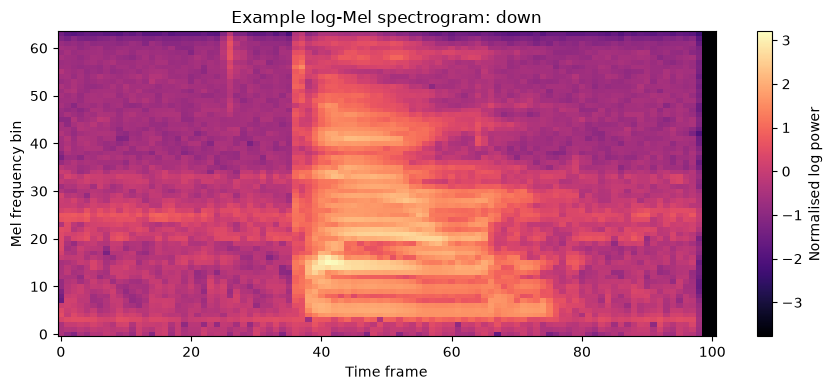

In [3]:
sample_features, sample_targets = next(iter(train_loader))
print('Batch shape:', tuple(sample_features.shape))
print('Target shape:', tuple(sample_targets.shape))
assert sample_features.ndim == 4 and sample_features.shape[1] == 1
assert torch.isfinite(sample_features).all()

plt.figure(figsize=(9, 4))
plt.imshow(sample_features[0, 0].numpy(), origin='lower', aspect='auto', cmap='magma')
plt.title(f'Example log-Mel spectrogram: {labels[int(sample_targets[0])]}')
plt.xlabel('Time frame')
plt.ylabel('Mel frequency bin')
plt.colorbar(label='Normalised log power')
plt.tight_layout()
plt.show()

## 4. Train the CNN

The model is trained on the full training split for up to six epochs. Spectrograms are calculated as batches are loaded, so training time depends on the available CPU resources. Validation performance is measured after each epoch, and the checkpoint with the highest validation macro-F1 is retained.

In [4]:
EPOCHS = 6
LEARNING_RATE = 1e-3
model = SmallAudioCNN(n_classes=len(labels))
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {parameter_count:,}')
training_started = time.perf_counter()
model, history = train_cnn(
    model, train_loader, validation_loader,
    epochs=EPOCHS, learning_rate=LEARNING_RATE, device=DEVICE
)
total_training_seconds = time.perf_counter() - training_started
print(f'Total training time: {total_training_seconds / 60:.1f} minutes')
display(history.round(4))

Trainable parameters: 156,156
Epoch 01/6 | train loss 0.9178 | val loss 0.9063 | val accuracy 0.6590 | val macro-F1 0.6659 | 1606.8s
Epoch 02/6 | train loss 0.5037 | val loss 0.6604 | val accuracy 0.7514 | val macro-F1 0.7217 | 2360.9s
Epoch 03/6 | train loss 0.4115 | val loss 0.5158 | val accuracy 0.8057 | val macro-F1 0.7769 | 2229.6s
Epoch 04/6 | train loss 0.3530 | val loss 0.4510 | val accuracy 0.8368 | val macro-F1 0.8045 | 1836.9s
Epoch 05/6 | train loss 0.3145 | val loss 0.4644 | val accuracy 0.8287 | val macro-F1 0.8012 | 3547.7s
Epoch 06/6 | train loss 0.2858 | val loss 0.4675 | val accuracy 0.8241 | val macro-F1 0.7951 | 3025.1s
Total training time: 243.6 minutes


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,epoch_seconds
0,1,0.9178,0.6852,0.9063,0.6590,0.6659,1606.7841
1,2,0.5037,0.8275,0.6604,0.7514,0.7217,2360.9324
2,3,0.4115,0.8602,0.5158,0.8057,0.7769,2229.6069
3,4,0.3530,0.8792,0.4510,0.8368,0.8045,1836.8898
4,5,0.3145,0.8949,0.4644,0.8287,0.8012,3547.7342
5,6,0.2858,0.9035,0.4675,0.8241,0.7951,3025.0569


## 5. Training curves

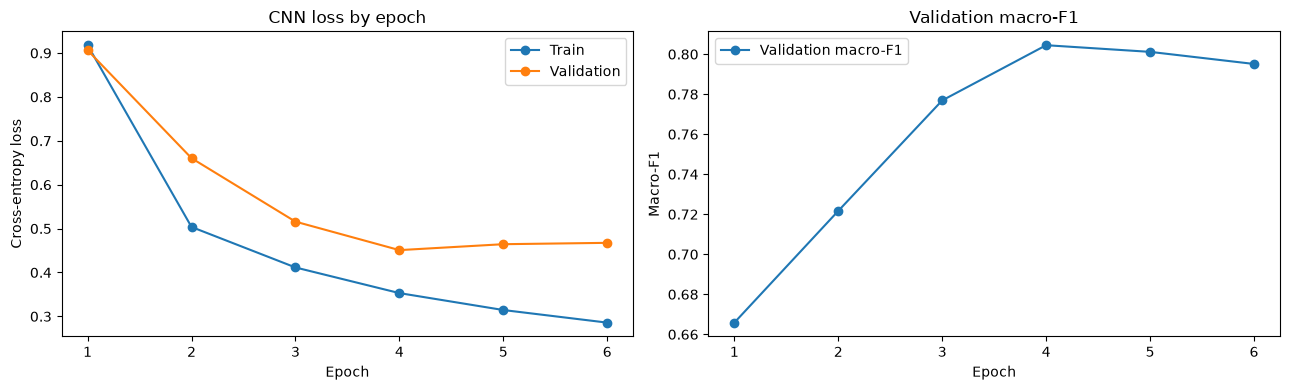

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history['epoch'], history['train_loss'], marker='o', label='Train')
axes[0].plot(history['epoch'], history['validation_loss'], marker='o', label='Validation')
axes[0].set_title('CNN loss by epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-entropy loss'); axes[0].legend()
axes[1].plot(history['epoch'], history['validation_macro_f1'], marker='o', label='Validation macro-F1')
axes[1].set_title('Validation macro-F1'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Macro-F1'); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Evaluate on validation data only

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
small_audio_cnn,0.8368,0.9107,0.7348,0.9107,0.8045


,precision,recall,f1-score,support
down,0.630,0.918,0.747,377.000
go,0.560,0.892,0.688,372.000
left,0.778,0.935,0.849,352.000
no,0.778,0.803,0.790,406.000
off,0.732,0.885,0.801,373.000
on,0.499,0.920,0.647,363.000
right,0.801,0.931,0.861,363.000
silence,0.803,1.000,0.891,61.000
stop,0.776,0.931,0.847,350.000
unknown,0.989,0.790,0.878,6278.000


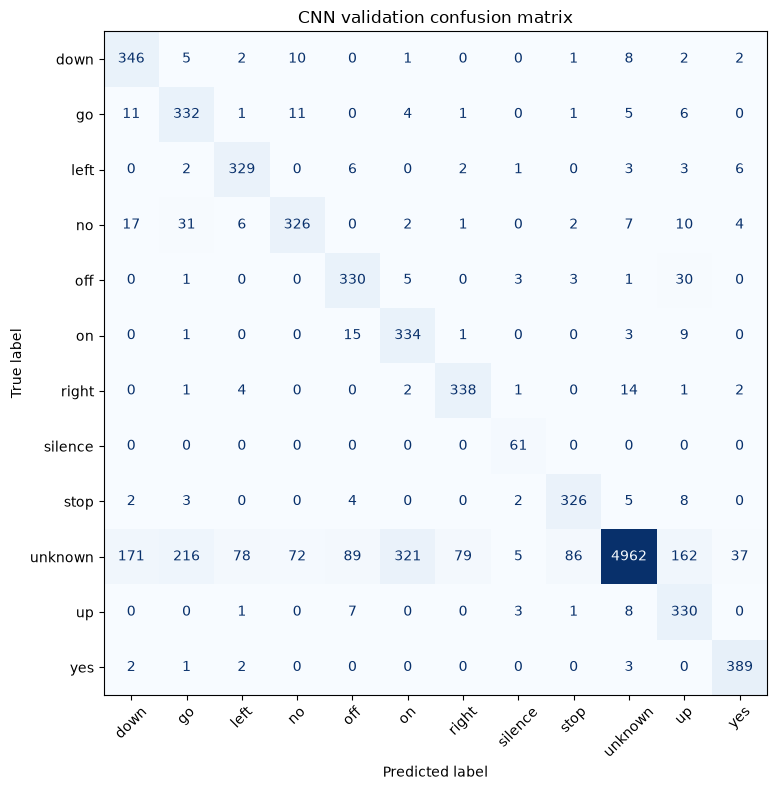

In [6]:
validation_result = evaluate_cnn(model, validation_loader, labels, device=DEVICE)
cnn_metrics = {key: validation_result[key] for key in [
    'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1'
 ]}
display(pd.DataFrame([cnn_metrics], index=['small_audio_cnn']).round(4))
display(pd.DataFrame(validation_result['report']).T.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=validation_result['confusion_matrix'], display_labels=labels
 ).plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
ax.set_title('CNN validation confusion matrix')
plt.tight_layout(); plt.show()

## 7. Compare with the classical baseline and save the CNN

In [7]:
comparison_rows = [{'model': 'small_audio_cnn', **cnn_metrics}]
classical_metrics_path = MODEL_DIR / 'validation_model_comparison.json'
if classical_metrics_path.is_file():
    classical = pd.read_json(classical_metrics_path)
    for row in classical.to_dict(orient='records'):
        comparison_rows.append(row)
else:
    print('Classical metrics JSON not found; showing CNN metrics only.')
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

checkpoint_path = MODEL_DIR / 'small_audio_cnn.pt'
save_cnn_bundle(model, labels, checkpoint_path, n_mels=64)
history_path = MODEL_DIR / 'cnn_training_history.csv'
history.to_csv(history_path, index=False)
metrics_path = MODEL_DIR / 'cnn_validation_model_comparison.json'
metrics_path.write_text(json.dumps(cnn_metrics, indent=2), encoding='utf-8')
print('Saved CNN checkpoint:', checkpoint_path)
print('Saved training history:', history_path)
print('Saved validation metrics:', metrics_path)
print('\nThe test split remains untouched. Do not report test performance until final model selection.')

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds,validation_prediction_seconds
0,small_audio_cnn,0.8368,0.9107,0.7348,0.9107,0.8045,NaN,NaN,NaN
1,linear_svm,0.5132,0.5089,0.3648,0.5089,0.4052,0.5367,19.9817,0.2929
2,random_forest,0.6488,0.2019,0.7667,0.2019,0.2229,0.5298,275.2528,2.5762


Saved CNN checkpoint: c:\Users\a\Documents\machine_learning_cycle\models\small_audio_cnn.pt
Saved training history: c:\Users\a\Documents\machine_learning_cycle\models\cnn_training_history.csv
Saved validation metrics: c:\Users\a\Documents\machine_learning_cycle\models\cnn_validation_model_comparison.json

The test split remains untouched. Do not report test performance until final model selection.


## 8. Interpretation

- Macro-F1 and balanced accuracy are used to compare models because the class distribution is uneven.
- Overall accuracy is considered alongside class-level metrics so that performance on smaller command classes is not overlooked.
- The confusion matrix is used to identify commands that are frequently misclassified.
- The CNN processes time-frequency patterns from log-Mel spectrograms, while the classical models use summary MFCC features. The comparison therefore considers both model architecture and audio representation.
- The test split remains reserved for the final evaluation after model selection using validation results.